# Real solution scattering to three-dimensional protein density


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`q`，shape `(1, 485)`，dtype `<f8`：Scattering-vector magnitude in angstrom$^{-1}$, including extrapolated low-frequency samples.；`intensity`，shape `(1, 485)`，dtype `<f8`：Experimental intensity in arbitrary intensity units; zero placeholders where measured_mask is false are not measurements.；`sigma`，shape `(1, 485)`，dtype `<f8`：Experimental one-standard-deviation uncertainty in the same intensity unit; extrapolated entries carry the source's mean early uncertainty and are not used as measured observations.；`smoothed_intensity`，shape `(1, 485)`，dtype `<f8`：Observation-derived GNOM smooth intensity in the same arbitrary intensity unit, including zero-angle extrapolation.；`measured_mask`，shape `(1, 485)`，dtype `|b1`：Dimensionless indicator of actual measurement; false marks only the extrapolated low-frequency entries.。未知量为64³归一化蛋白对比电子密度，Å^-3。

获取模型：三维密度Fourier模平方在球方向平均形成SAXS曲线，单位积分密度规范。

如何恢复：src.solvers.reconstruct：DENSS reciprocal-shell幅度投影、real-space支持/连通/中心迭代。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell2主动全解；3及5/7/9多图保留原始曲线/密度、五独立starts、半空间权重纠正、敏感性及歧义。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留4个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。没有独立3D蛋白真值；smoothed_intensity来自观测拟合而非目标密度，必须保留其来源。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


This notebook recovers a $64^3$ three-dimensional normalized contrast-density field from the complete one-dimensional, spherically averaged SAXS curve of lysozyme, and actively computes every plotted fresh comparison. It distinguishes the published method, unmodified current source, qualified corrected original runs, and fresh local computation. There is no voxelwise molecular truth. A scattering-compatible low-resolution density is not an identified atomic structure.

The real GNOM profile contains485 frequencies;468 are actual measurements. The other17 extrapolate to zero angle and are explicitly masked. The smooth fit supplies legitimate same-observation preprocessing, not a hidden target. Density is normalized to integral1 in a240A periodic box,64 voxels per axis,3.75A spacing. The source-provided GNOM dimension estimate40A is a soft prior, not a true molecular support mask.

The published23-page official supplement (Notes1–5 including executable mathematics) was read. Its12 experimental systems are not this lysozyme demo. The main paper's full article remains paywalled; no unsupported full-text or all-paper reproduction claim is made.

## 2. Data

The complete supplied profile contains485 frequencies. Of these468 have experimental measurements;17 low-frequency entries are a smooth extrapolation only. The mask separates them explicitly. The smooth fit was obtained from the same experimental curve by indirect Fourier transformation before density reconstruction. It is an observation-derived preprocessing result and contains no hidden spatial model.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| q | (1, 485) | float64 | Scattering-vector magnitude in angstrom$^{-1}$, including extrapolated low-frequency samples. |
| intensity | (1, 485) | float64 | Experimental intensity in arbitrary intensity units; zero placeholders where measured_mask is false are not measurements. |
| sigma | (1, 485) | float64 | Experimental one-standard-deviation uncertainty in the same intensity unit; extrapolated entries carry the source's mean early uncertainty and are not used as measured observations. |
| smoothed_intensity | (1, 485) | float64 | Observation-derived GNOM smooth intensity in the same arbitrary intensity unit, including zero-angle extrapolation. |
| measured_mask | (1, 485) | bool | Dimensionless indicator of actual measurement; false marks only the extrapolated low-frequency entries. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Specimen | Lysozyme solution | dimensionless | Author-provided real SAXS example |
| Actual measured q range | 0.00982 to 0.2793 | angstrom$^{-1}$ | All468 measured points remain evaluated |
| Profile q range including extrapolation | 0 to 0.2793 | angstrom$^{-1}$ | All485 supplied samples |
| Zero-angle smooth intensity | 0.04591 | arbitrary intensity unit | Fixed normalization value from smoothed_intensity at q=0 |
| Maximum dimension estimate | 40.0 | angstrom | Observation-derived GNOM estimate; soft compactness information, not a hidden atomic model |
| Source indirect transform | GNOM4.6,2017-05-04 | dimensionless | Supplied profile header provenance |
| Box side | 240.0 | angstrom | Periodic Fourier box embedding the compact object |
| Grid side | 64 | voxel | Same count on x,y,z axes |
| Voxel spacing | 3.75 | angstrom | Uniform isotropic spacing; origin at index32 |
| Density normalization | 1.0 | dimensionless | Total integrated normalized contrast density |
| Particle orientation | Not measured | dimensionless | Random tumbling produces the spherical intensity average |
| Instrument angular resolution and covariance | Not supplied | dimensionless | No extra smearing kernel or covariance is inferred from a hidden model |
| Absolute electron count/concentration | Not supplied | dimensionless | Output is a normalized map, not absolute electrons per volume |

## 3. Physics

### Spherically averaged scattering

Let $\rho(\mathbf r)$ be the normalized contrast electron density in A$^{-3}$ and $F(\mathbf q)=\int\rho(\mathbf r)e^{-i\mathbf q\cdot\mathbf r}d^3\mathbf r$ its structure factor. The observation $I(q)/I(0)$ is the spherical mean of $|F|^2$ at radius $q$. Here $\mathbf r$ is position in A and $\mathbf q$ spatial frequency in A$^{-1}$. Fourier phases and molecular orientation are lost.

## 4. Method

### Fourier and real-space projection inverse

The local method explicitly computes Fourier transforms, correctly weighted spherical averages, amplitude projections, real-space positivity/support constraints, shrinkwrap and connectedness. If $J$ is the current shell intensity and $T$ the observation-derived target, amplitudes are multiplied by $\sqrt{T/J}$; phases remain. The target uses linear interpolation of the supplied GNOM fit and a declared $q^{-4}$ continuation beyond measured data. A real FFT stores one Fourier half-space: weights1 on zero/Nyquist planes and2 elsewhere exactly recover a fullFFT shell average.

The original current implementation omitted those multiplicities. Unmodified runs remain archived. The qualified oracle changes only this shell average for both intensity and shell-coordinate radius. Independent fullFFT and90degree rotation tests establish the correction. This task uses user-configurable oversampling6; it does not claim identical parameters or discretization to every2018 paper experiment.

The real-space error reduction sets outside-support and negative values to zero. A periodic Gaussian blur and20% threshold updates the support, with sigma3 decaying by0.99 toward1.5 voxels. Source-scheduled integer centering and connected-component selection are explicit. Stopping uses the source's pre-final weighted-amplitude-fit chi2 monitor:100-step coefficient of variation below0.01, at most6000 iterations. The final source Fourier projection is retained, including signed tails; no clipping or alternate output stage improves its reported quality.

Let $T(q)$ be the observation-derived radial target and $J(q)$ the correctly full-space-weighted shell intensity. Each projection rescales complex Fourier coefficients by $\sqrt{T/J}$, then applies real-space support/positivity, scheduled shrinkwrap and connected-component selection. Unit-integral density has angstrom$^{-3}$ units; internal per-voxel mass is divided by the 3.75 angstrom voxel volume only on output. Real-FFT shell weights are one on zero/Nyquist planes and two elsewhere. This is an explicitly corrected shell average, not unchanged upstream reproduction. The final Fourier projection retains signed tails; later display alignment never modifies the submitted density.

## 5. Results

### Identifiable evaluation and independent quality checks

The standalone Judge independently computes a full complex FFT of the submitted map and compares **all468 measured frequencies** after fixed normalization by the observed smooth $I(0)$. Its chi2 is mean squared residual divided by supplied variance; it fits neither amplitude nor background. It also checks integrated density, negative/positive mass, soft compactness, connected high-density core, the declared Porod continuation and scattering radius of gyration against a weighted Guinier fit of the actual data.

The source's reported final chi2 and radius use an intensity array before the final Fourier projection. Those monitor values differ from recalculating the returned final density and are labeled separately. The final signed tails are visible and quantified. Five independent qualified-original runs fixed thresholds before local evaluation. Explicit zero, constant, sphere, single-voxel, checkerboard and high-frequency-modulated maps fail; inverse reconstruction cannot be replaced with those simple fields.

No hidden model alignment or random-seed truth enters the Judge. Rotations, translations and handedness are gauges. More general shape ambiguities remain even after alignment. Display alignment below uses coarse-grid inertia starts over all axis permutations/signs and Powell rigid refinement, including handedness; its interpolated images and diagnostic cosines never modify the evaluated raw density.

Full measured-data residuals and original-start ensembles are separate from display-aligned density comparisons. The 17 extrapolated low-q samples and $q^{-4}$ high-q continuation remain identified priors; the independent Judge evaluates the 468 actual measured frequencies without fitting a gain or background.


In [1]:
from pathlib import Path
import sys,time,json,os,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.solvers import reconstruct
from src.visualization import make_figures,export_figures
data=load_observations(ROOT/'data/raw_data.npz')
provenance=json.loads((ROOT/'notebooks/reference_outputs/measurements.json').read_text(encoding='utf8'))
print(json.dumps(provenance['source_categories'],indent=2))
print('Actual measured frequencies:',int(data['measured_mask'].sum()))


{
  "paper": "2018 published method; full official23-page supplement actually read; main paper subscription preview only. Twelve paper systems differ from author-provided real lysozyme demo used here. No paper metrics are substituted for this run.",
  "unmodified_original": "Exact current upstream5009b1c659599423a55c31372ed6a88f1925417f, original rFFT half-space averaging, retained separate comparison;32/64-grid trials in private archive.",
  "qualified_original": "Only shell Hermitian multiplicity corrected, independently equal fullFFT and90degree rotations;5 independent64^3 original runs. Other selected original iterations/projections/shrinkwrap unchanged.",
  "fresh_cleaned": "Active local reconstruction below; no original library import, no cached substitution.",
  "truth": "No spatial truth; different shape-compatible densities are not failed by hidden-reference NCC."
}
Actual measured frequencies: 468


In [2]:
start=time.perf_counter()
fresh=reconstruct(data,return_history=True)
canonical_runtime=time.perf_counter()-start
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=fresh['reconstruction'])
spec=importlib.util.spec_from_file_location('standalone_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(ROOT/'output/reconstruction.npz')
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False)+'\n',encoding='utf8')
assert exit_code==0,report
print('Fresh canonical runtime(s):',canonical_runtime,'iterations:',fresh['history']['iterations'])
print(json.dumps(report,indent=2))
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as f:upstream={key:f[key] for key in f.files}
parity=np.sqrt(np.mean((fresh['reconstruction']-upstream['reconstruction'])**2))/np.ptp(upstream['reconstruction'])
print('Independent qualified-original comparison, dynamic-range NRMSE:',parity)


Fresh canonical runtime(s): 9.198467599999276 iterations: 965
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "chi2": 1.071470354273987,
    "mass_error": 2.220446049250313e-16,
    "negative_mass_fraction": 0.09431850362001754,
    "outside_mass_fraction": 0.07910601374264946,
    "disconnected_fraction": 0.0,
    "porod_tail_relative_rms": 5.023619810272898e-14,
    "rg_relative_error": 0.023920141582047187,
    "reference_scattering_nrmse": 9.388214061534874e-17
  },
  "thresholds": {
    "chi2": {
      "comparison": "<=",
      "boundary": 1.1786173897013836
    },
    "mass_error": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "negative_mass_fraction": {
      "comparison": "<=",
      "boundary": 0.13233774201800175
    },
    "outside_mass_fraction": {
      "comparison": "<=",
      "boundary": 0.11198335350661684
    },
    "disconnected_fraction": {
      "comparison": "<=",
      "boundary": 0.01
    },
    "porod_tail_relative_rms": {
      "com

seed42 fresh runtime(s) 13.52141280000069 iterations 1609


seed43 fresh runtime(s) 4.965476999997918 iterations 686


tol005 fresh runtime(s) 16.825686700001825 iterations 1571


tol020 fresh runtime(s) 5.259733099999721 iterations 478


{
  "canonical": {
    "chi2": 1.071470354273987,
    "mass_error": 2.220446049250313e-16,
    "negative_mass_fraction": 0.09431850362001754,
    "outside_mass_fraction": 0.07910601374264946,
    "disconnected_fraction": 0.0,
    "porod_tail_relative_rms": 5.023619810272898e-14,
    "rg_relative_error": 0.023920141582047187,
    "reference_scattering_nrmse": 9.388214061534874e-17
  },
  "unmodified_original": {
    "chi2": 1.1047088504060436,
    "mass_error": 2.220446049250313e-16,
    "negative_mass_fraction": 0.09339307423283298,
    "outside_mass_fraction": 0.07729493091972467,
    "disconnected_fraction": 0.0,
    "porod_tail_relative_rms": 0.0215469779679503,
    "rg_relative_error": 0.018781033480139438
  },
  "seed42": {
    "chi2": 1.071470354273984,
    "mass_error": 0.0,
    "negative_mass_fraction": 0.08663064986159291,
    "outside_mass_fraction": 0.07233191839730081,
    "disconnected_fraction": 0.0,
    "porod_tail_relative_rms": 5.119884558015951e-14,
    "rg_relative_e

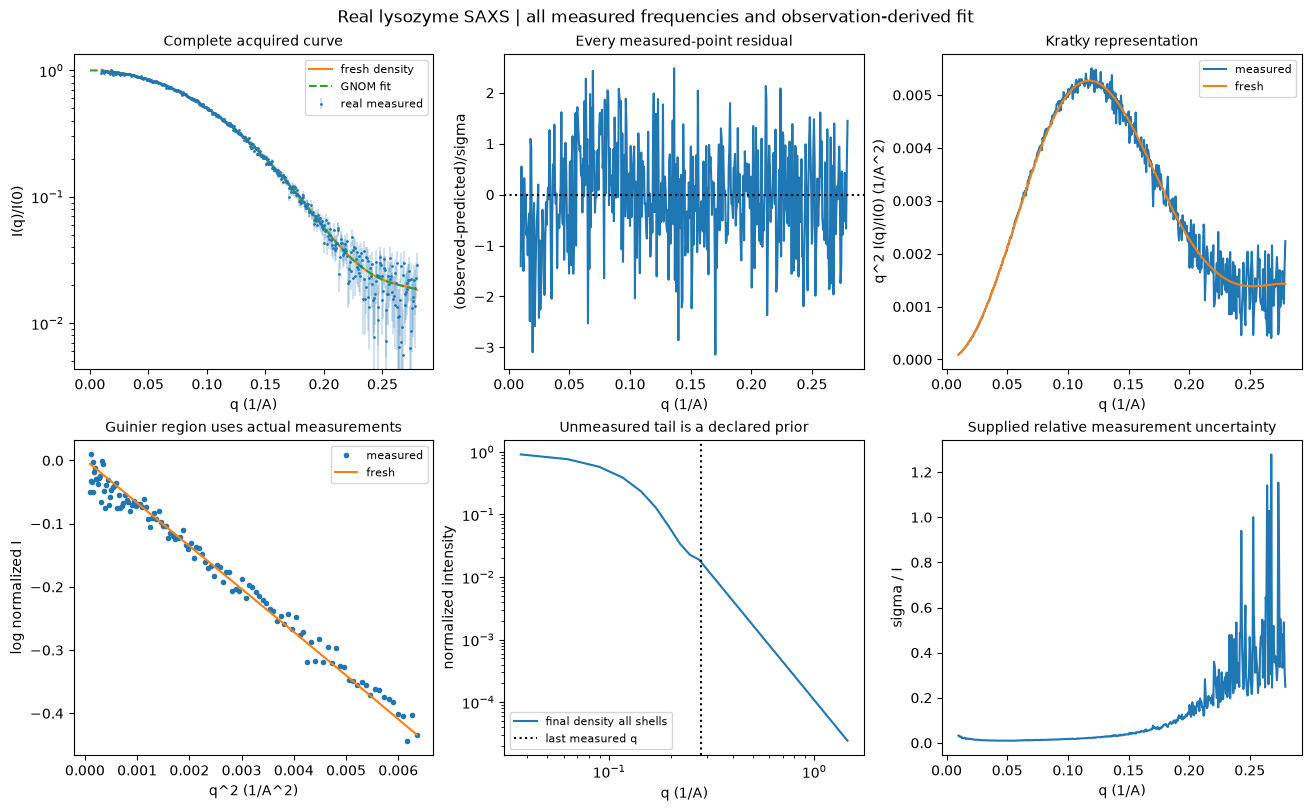

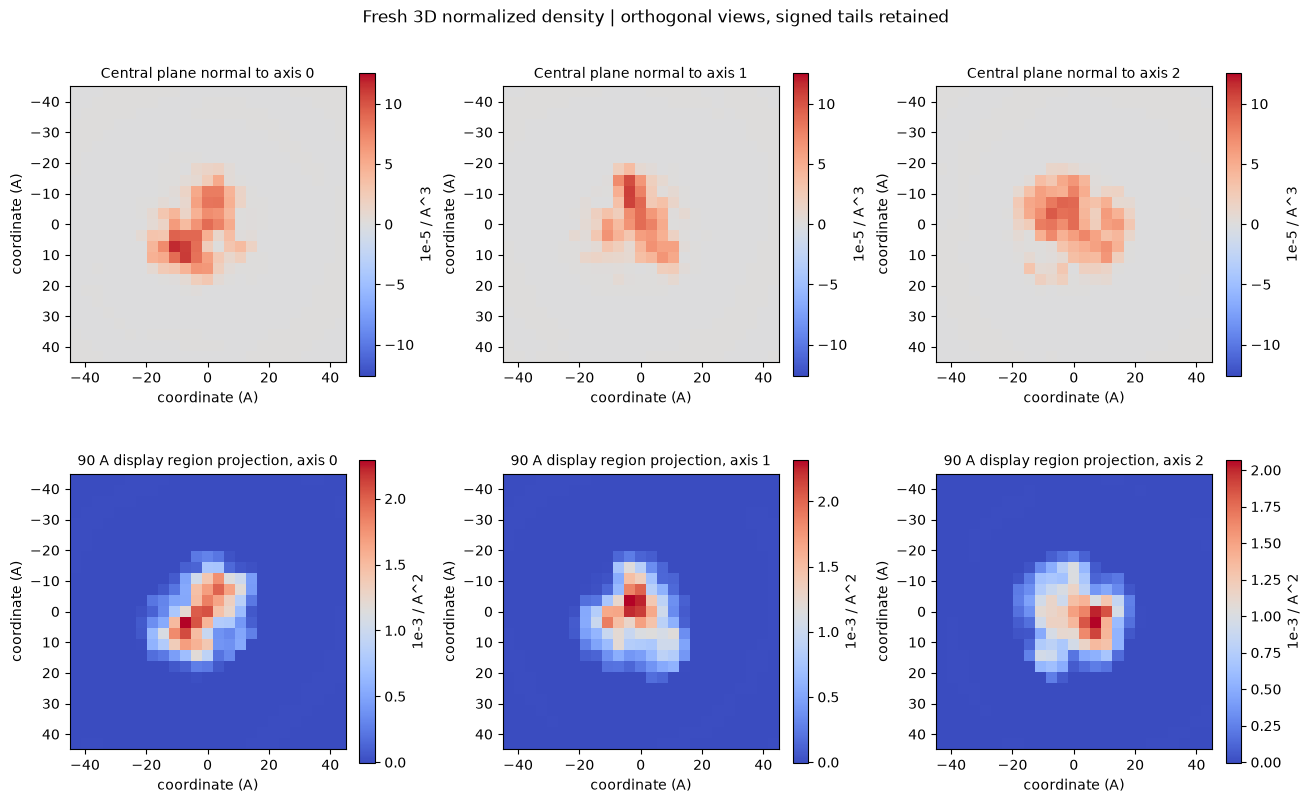

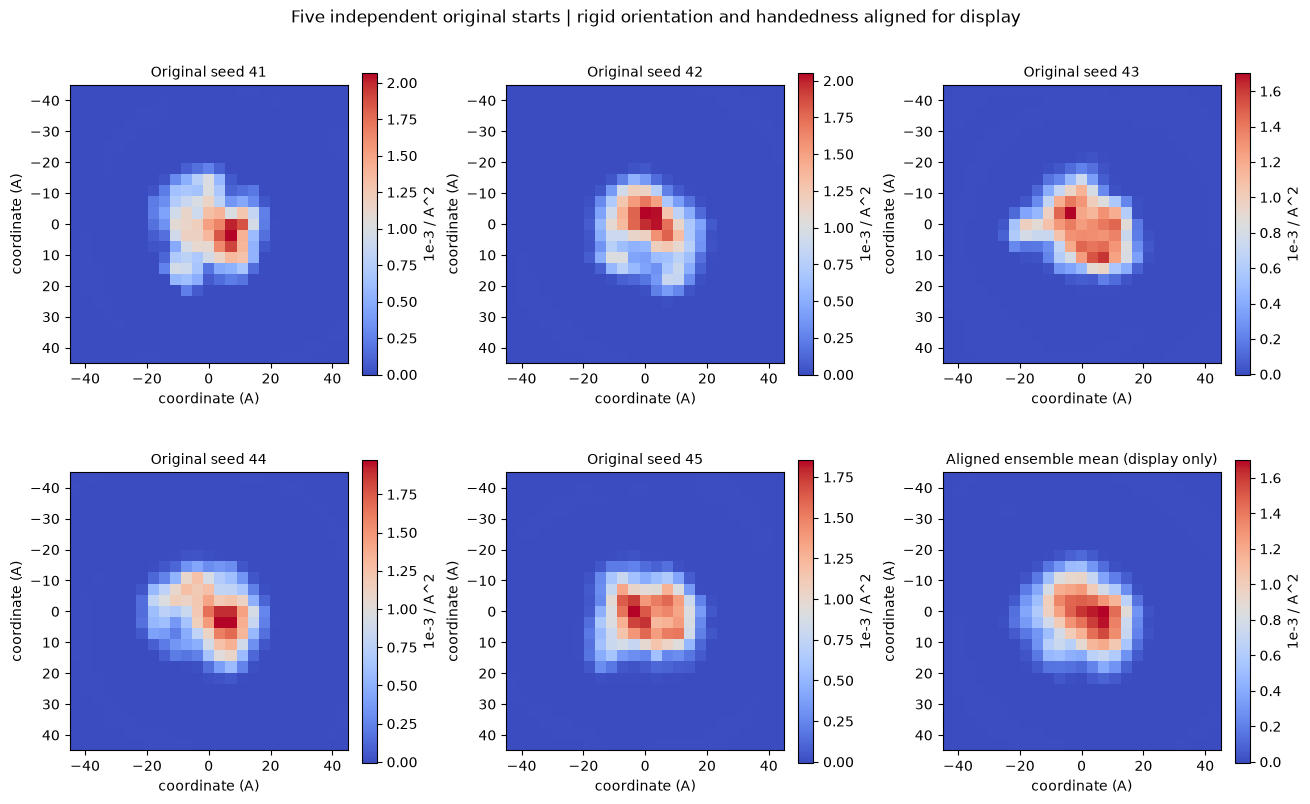

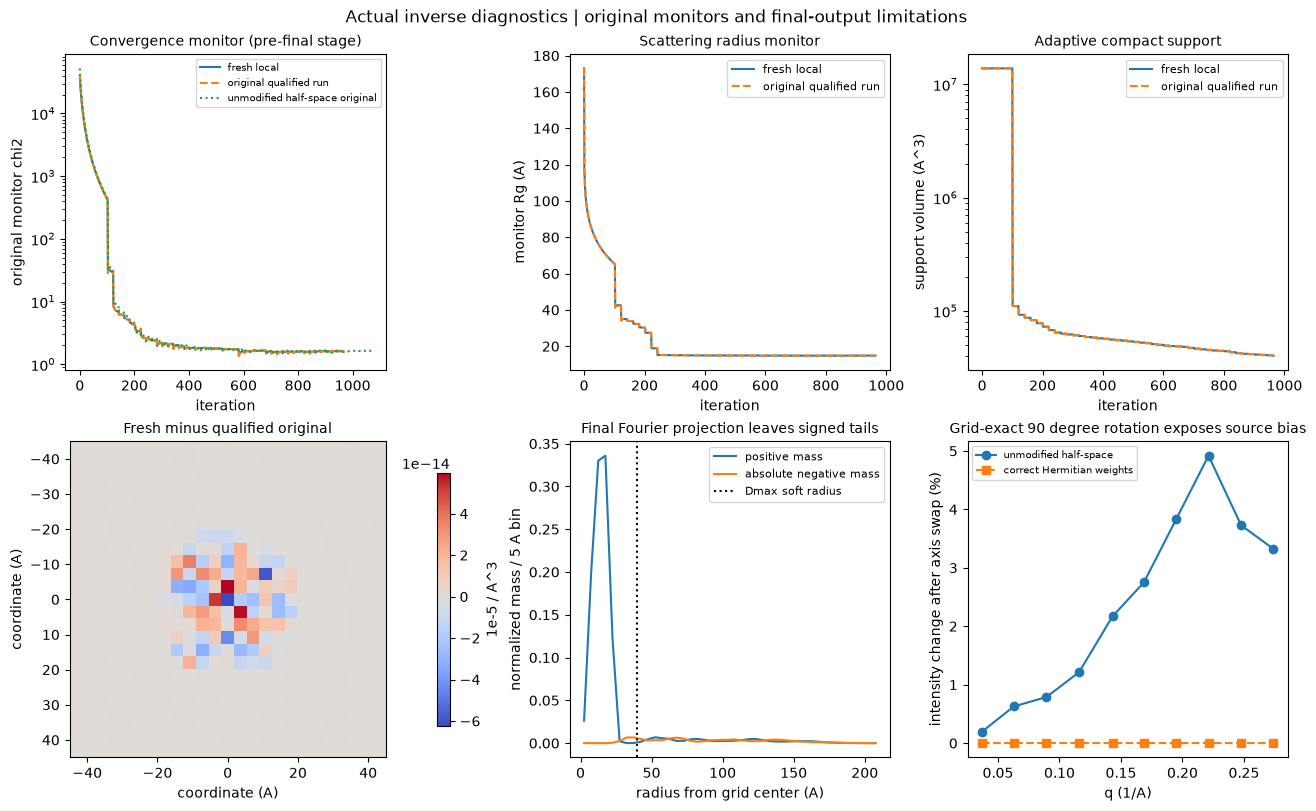

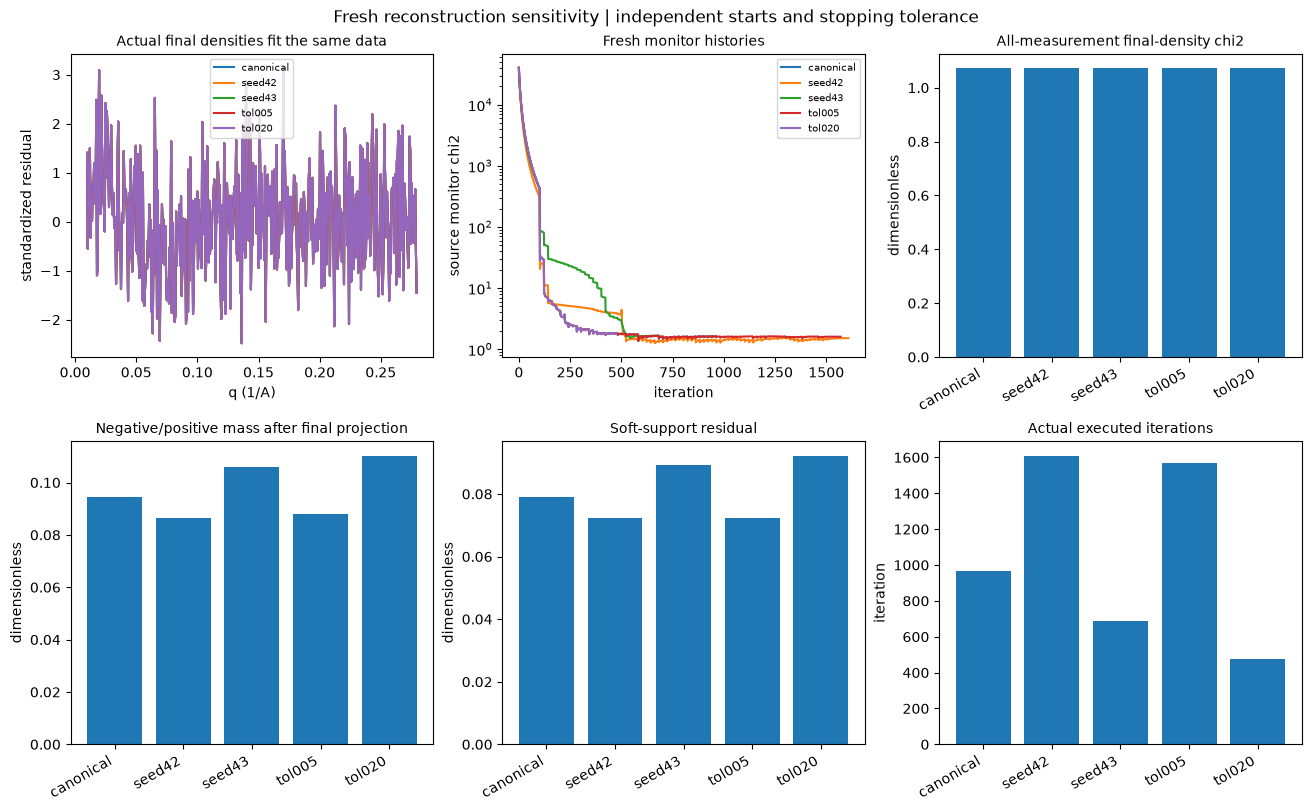

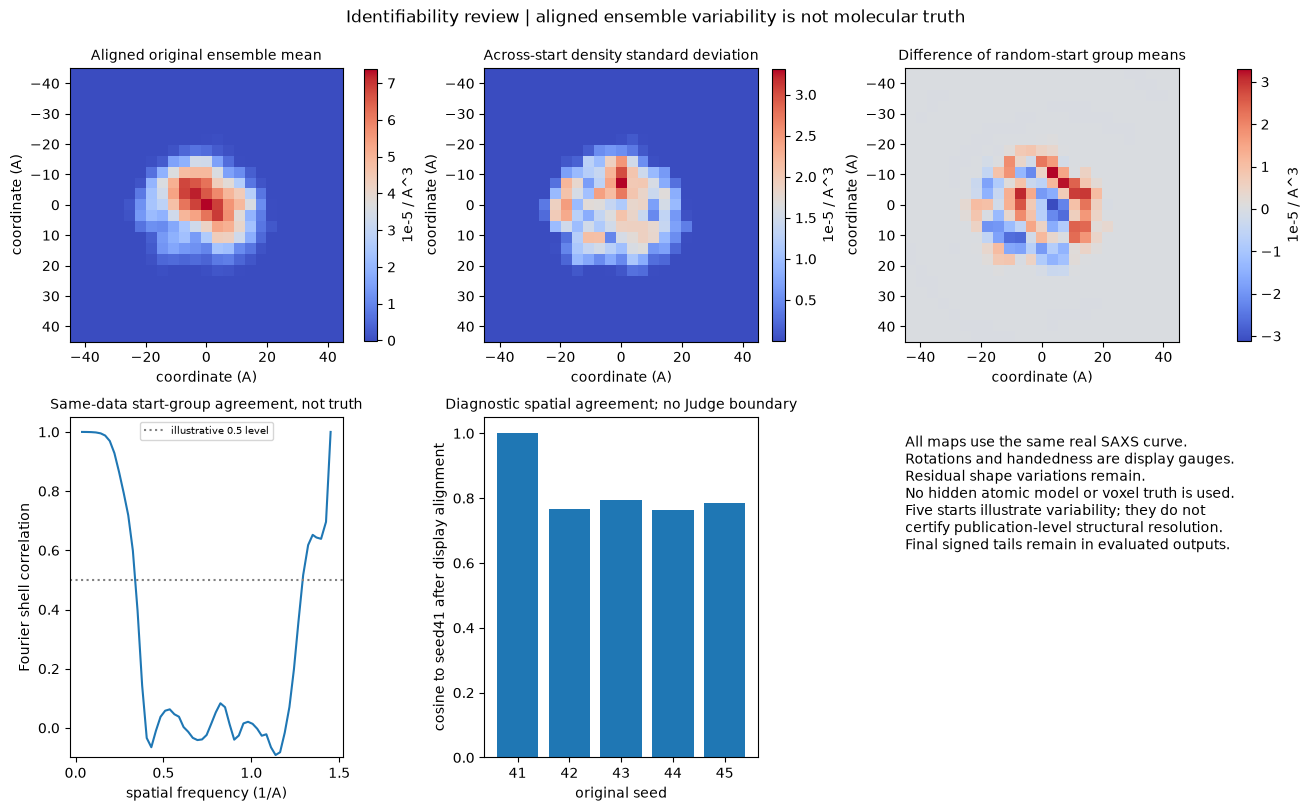

In [3]:
comparisons={}
comparison_runtimes={}
for name,parameters in [('seed42',{'seed':42}),('seed43',{'seed':43}),('tol005',{'convergence_fraction':.005}),('tol020',{'convergence_fraction':.02})]:
    start=time.perf_counter()
    comparisons[name]=reconstruct(data,return_history=True,**parameters)
    comparison_runtimes[name]=time.perf_counter()-start
    print(name,'fresh runtime(s)',comparison_runtimes[name],'iterations',comparisons[name]['history']['iterations'])
scores={'canonical':report['metrics'],'unmodified_original':judge.physical_metrics(upstream['unmodified_halfspace_density'][0],data)}
for name,result in comparisons.items():scores[name]=judge.physical_metrics(result['reconstruction'][0],data)
print(json.dumps(scores,indent=2,allow_nan=False))
figures,numeric_sources,figure_metrics=make_figures(data,fresh,upstream,comparisons,scores)
figure_metrics['canonical_runtime_s']=canonical_runtime
figure_metrics['fresh_comparison_runtime_s']=comparison_runtimes
destination=os.environ.get('IMAGING101_FIGURE_DIR')
if destination:export_figures(figures,numeric_sources,figure_metrics,destination)


### Measured-data fidelity and fresh spatial reconstruction

The first two groups show every real measurement, observation uncertainty, GNOM smooth fit, actual returned density scattering, residuals, signed orthogonal density slices and projections. The90A display region is labeled; numerical evaluation retains the entire240A box. Unmeasured high-frequency continuation is a declared prior rather than additional acquired data.


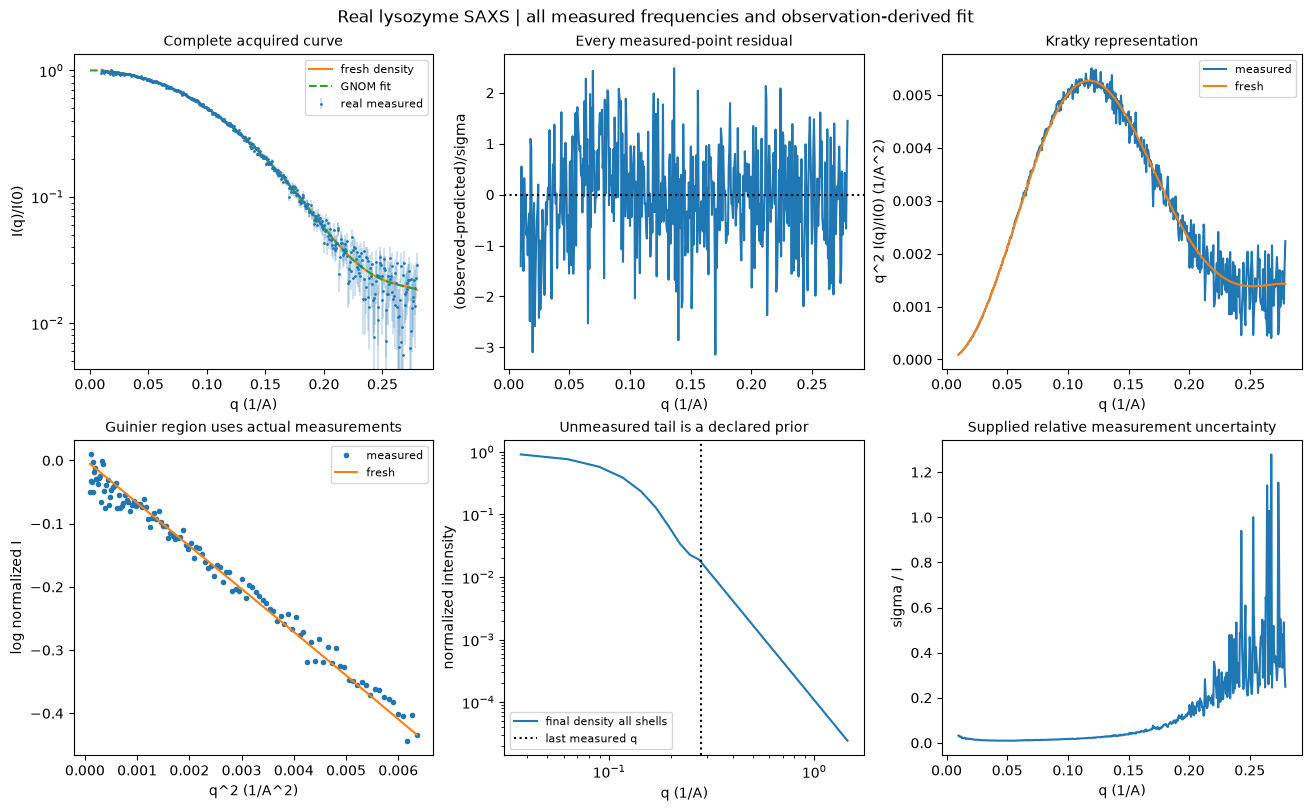

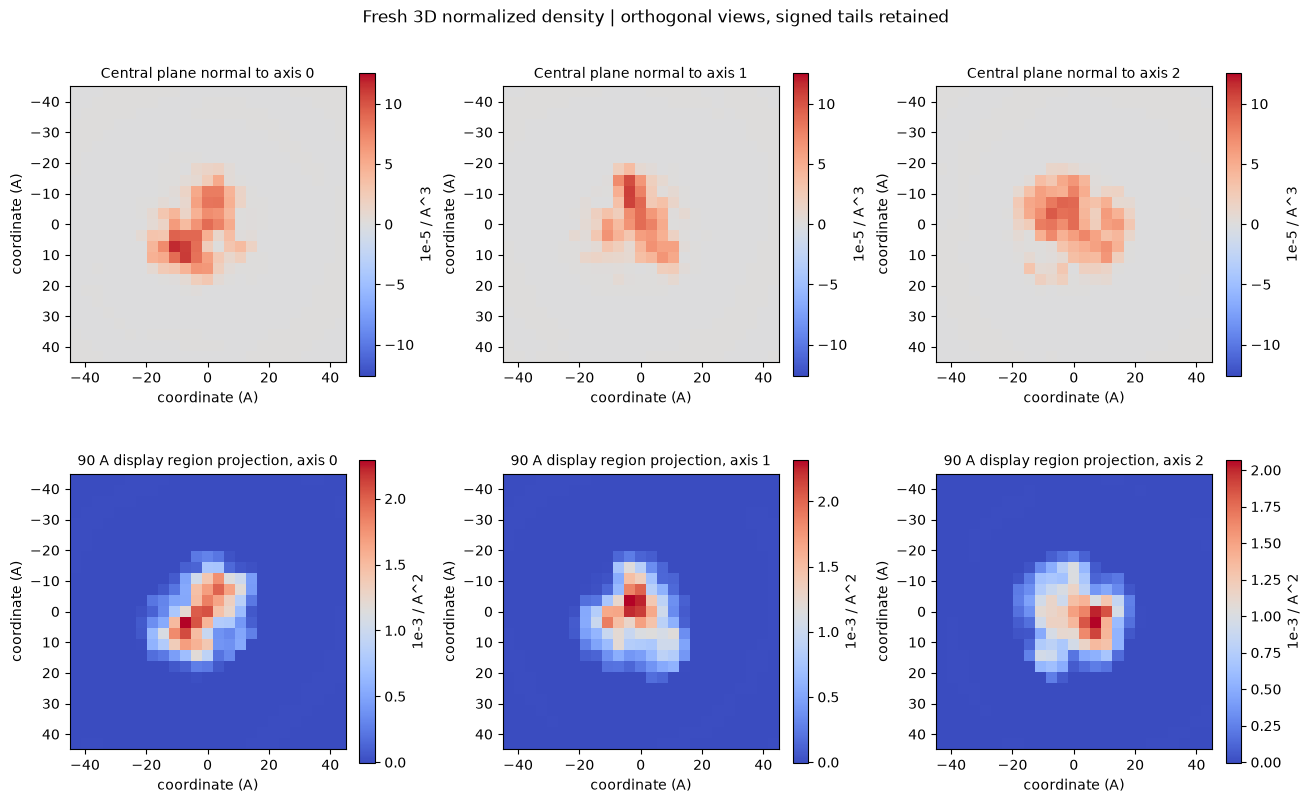

In [4]:
display(figures[0]);display(figures[1])

### Independent starts and original numerical diagnostics

Five independent original solutions are rigidly aligned including handedness for visualization, together with their ensemble mean. The next group preserves the source-relevant chi2, radius and support-volume histories and shows fresh/original agreement, actual signed tails and recalculated final-output metrics. No reconstruction is labeled ground truth.
The unmodified current-source monitor is also plotted. Its half-space shell average changes by4.918% under an exact90degree axis exchange on the actual returned density, while corrected multiplicities change only at1.1e-15 relative roundoff. This independent grid-symmetry test justifies the explicitly qualified correction.


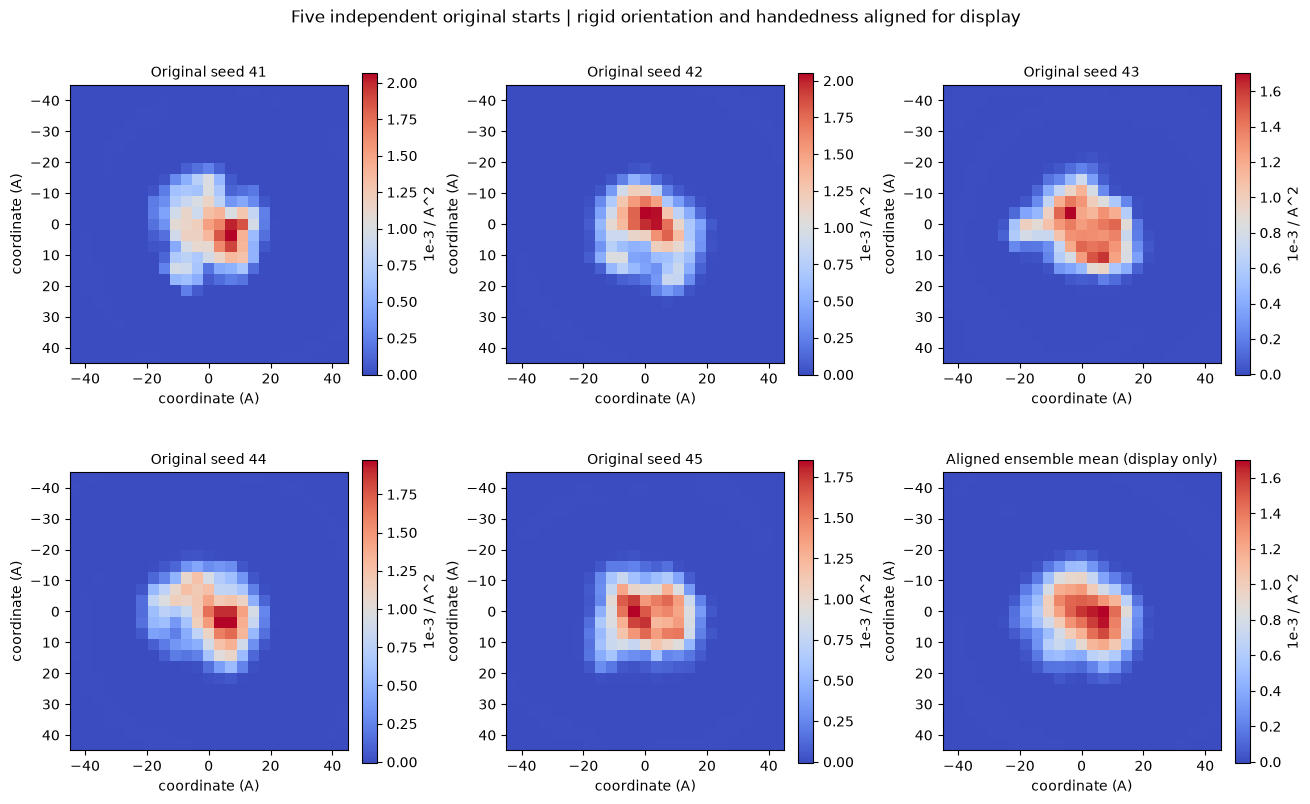

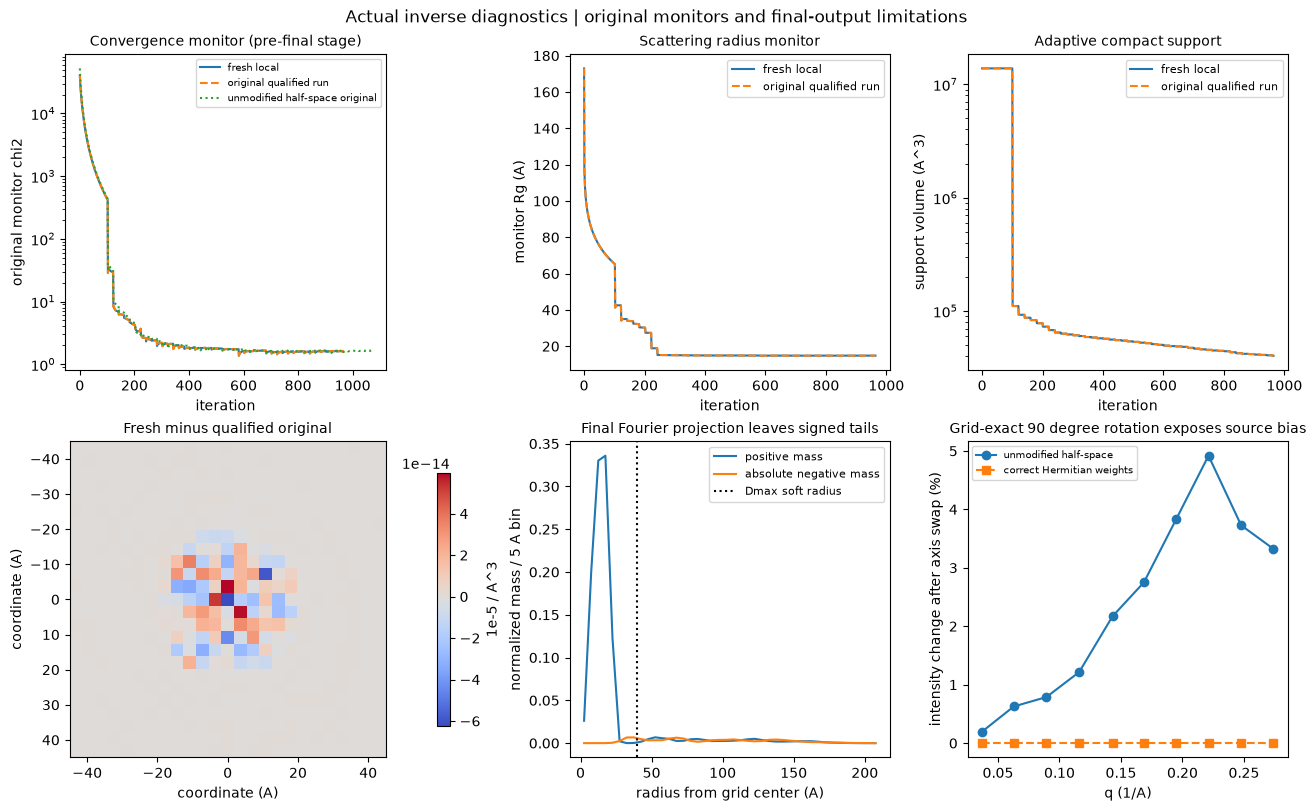

In [5]:
display(figures[2]);display(figures[3])

### Fresh sensitivity and remaining structural ambiguity

Every comparison below was reconstructed in this execution. Seeds42/43 change initialization. Tolerances0.005/0.020 change only the stopping coefficient of variation; the canonical0.01 method remains fixed. Differences in tails or stopping cost are measured rather than filled from an archive.

The final group shows aligned ensemble mean, standard deviation, and differences between groups of independent starts. Fourier shell correlation between these groups measures **same-data random-start consistency**; it is not an independent experimental validation or a certified molecular resolution. Only five starts are used here, whereas broader structural publication claims require more validation. Atomic structure truth, other paper samples and bead-model comparisons are unavailable for this bound demo, so they are neither fabricated nor silently relabeled as reproduced evidence.


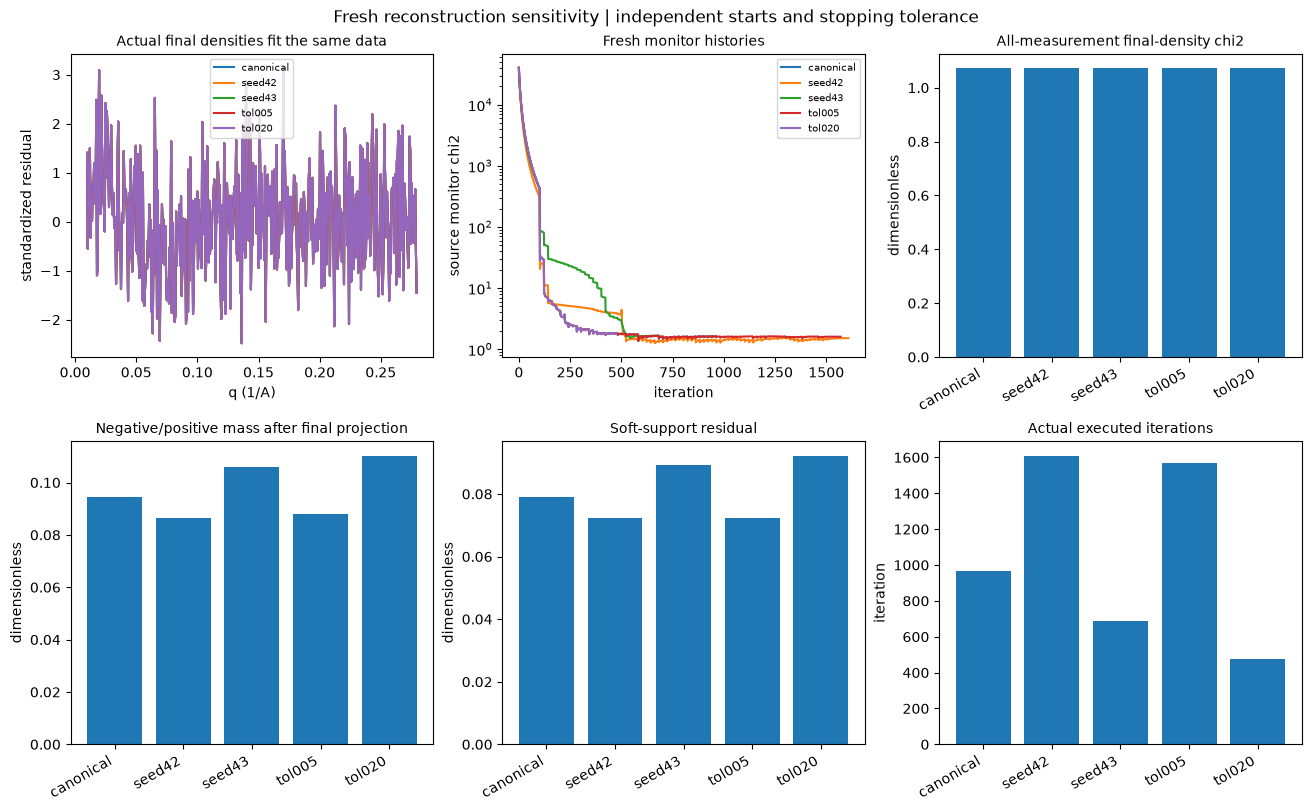

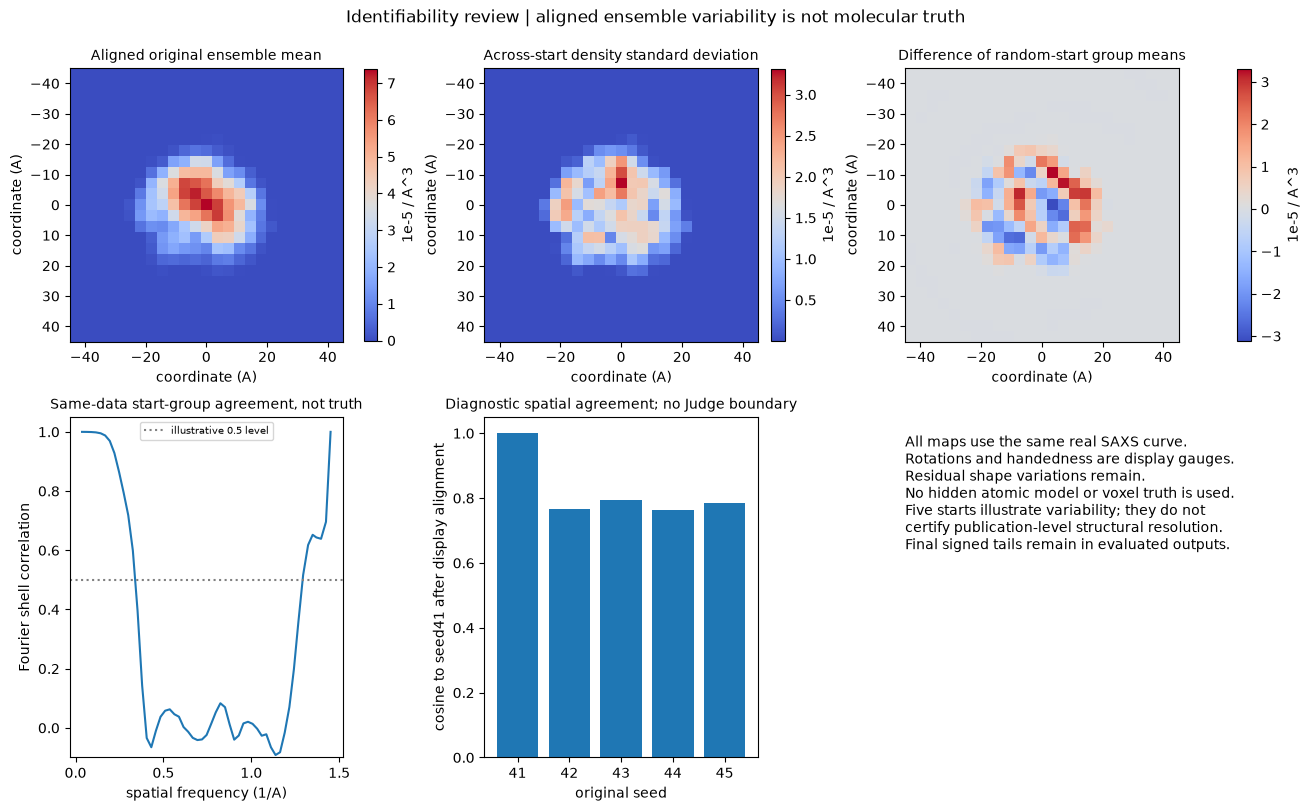

Final display-only alignment diagnostics:
[
  {
    "core_registration_cosine": 1.0,
    "aligned_raw_density_cosine": 1.0,
    "handedness_determinant": 1.0
  },
  {
    "core_registration_cosine": 0.9595778200402169,
    "aligned_raw_density_cosine": 0.7663473496841077,
    "handedness_determinant": 1.0000000000000009,
    "matrix_output_to_input": [
      [
        -0.800223353736694,
        0.5602402378420078,
        0.2139473300537522
      ],
      [
        -0.4504648687047317,
        -0.7970398921234162,
        0.40225466116220804
      ],
      [
        0.39588380390870753,
        0.2255178180690476,
        0.8901784807195399
      ]
    ],
    "offset_output_to_input_voxel": [
      33.38472535731068,
      59.319483866740555,
      -16.481246177932775
    ]
  },
  {
    "core_registration_cosine": 0.9641049547192226,
    "aligned_raw_density_cosine": 0.7942953510868102,
    "handedness_determinant": -0.9999999999999997,
    "matrix_output_to_input": [
      [
        

In [6]:
display(figures[4]);display(figures[5])
for fig in figures:plt.close(fig)
print('Final display-only alignment diagnostics:')
print(json.dumps(figure_metrics['display_alignment'],indent=2))


## 6. Conclusion

### Interpretation

The explicit local method reproduces the qualified original numerical method on the complete real bound curve and passes independently recalculated scattering/physical checks. It retains final Fourier-projection positivity/support residuals. Compatible densities can differ even after rotation and handedness alignment. These results support a reproducible constrained inverse task, without claiming a unique three-dimensional molecular structure or atomic detail.
